# 09 - Reservoir Quality and Net Pay

**Part A - Petrophys Curriculum**

This is where the whole Part A pipeline comes together. Having computed clay
volume, porosity, water saturation (notebook 07) and permeability (notebook 08), we
now answer the questions a decision-maker actually asks:

- **How good is the rock?** - flow-zone indicators (RQI/FZI) and flow units.
- **Where is the moveable hydrocarbon?** - bulk-volume water (BVW) and the moveable-
  hydrocarbon index (MHI).
- **How much of the interval is pay?** - the three-stage net-pay flag with porosity,
  saturation and clay cutoffs.
- **How much hydrocarbon is in place?** - volumetrics (HCPV, OOIP, OGIP).

We tie it end-to-end on **30/6-5**, producing a net-pay flag track and a summary
table.

## Learning goals

By the end of this notebook you will be able to:

- Compute Rock Quality Index (RQI), normalised porosity ($\phi_z$) and Flow Zone
  Indicator (FZI) with `petrophys.evaluation` and group rock into **flow units**.
- Compute bulk-volume water (BVW) and the moveable-hydrocarbon index (MHI), and
  read what they say about producibility.
- Apply the **three-stage net-pay** logic (net rock -> net reservoir -> net pay)
  with `calculate_net_pay` / `NetPayModule` and `Cutoffs`.
- Run volumetrics with `calculate_hcpv`, `calculate_ooip`, `calculate_ogip` from
  `petrophys.evaluation.summaries`.
- Assemble a net-pay flag track and a one-line reservoir summary.

## Why this matters

A reservoir is not uniformly good. Reservoir-quality workflows sort the rock and
then keep only the part that will actually produce:

- **RQI / FZI** convert porosity and permeability into a *hydraulic* quality metric.
  Rocks with the same FZI have the same pore-throat character and plot on one line -
  a **flow unit**. This is how you zone a reservoir into layers that behave alike.

  $$ RQI = 0.0314\sqrt{k/\phi_e}, \quad \phi_z = \frac{\phi_e}{1-\phi_e}, \quad
     FZI = \frac{RQI}{\phi_z} $$

- **BVW** $= \phi_e \times S_w$ is the fraction of *bulk* rock that is water. In a
  rock at irreducible water, BVW is roughly constant - a hallmark of a clean,
  above-transition-zone reservoir that will produce water-free.

- **MHI** $= S_w / S_{xo}$ compares deep and flushed-zone water. A low MHI ($<0.7$)
  means mud filtrate pushed hydrocarbon out of the near-wellbore rock, so the
  hydrocarbon is **moveable**.

- **Net pay** is the thickness that passes *all* cutoffs. Volumetrics then turn net
  pay, porosity and $S_w$ into barrels or cubic feet in place.

### Prerequisites

Assumes notebooks 07 (saturation) and 08 (permeability). We recompute Vcl,
porosity, $S_w$, $S_{xo}$ and a core-calibrated permeability inline so this
notebook runs standalone.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import petrophys
from petrophys.io import read_las

print('petrophys', petrophys.__version__)

petrophys 0.1.0


## 1. Rebuild the full curve set on 30/6-5

We reconstruct every input the reservoir-quality tools need over the BAAT Group
reservoir (2841-2958 m): $V_{cl}$, effective porosity, deep and shallow
resistivity, $S_w$, $S_{xo}$, and a **core-calibrated** permeability (the transform
we fitted in notebook 08).

In [2]:
from petrophys.interpretation.clay_volume import vcl_from_gr
from petrophys.interpretation.porosity import density_porosity, neutron_porosity
from petrophys.interpretation.saturation import archie, calculate_sxo
from petrophys.interpretation.core_analysis import fit_poro_perm_transform
from petrophys.interpretation.core_analysis.calibration import core_data_from_well

well = read_las(petrophys.sample('30_6-5'))
TOP, BASE = 2841.0, 2958.0
res = well.depth_slice(TOP, BASE)

depth = res.depth
gr    = res.get('GR').data
rhob  = res.get('RHOB').data
nphi  = res.get('NPHI').data
rt    = res.get('RDEP').data
rxo   = res.get('RSHA').data

vcl  = vcl_from_gr(gr, np.nanpercentile(gr, 5), np.nanpercentile(gr, 95))
phie = np.clip((density_porosity(rhob) + neutron_porosity(nphi)) / 2.0, 0.0, 0.40)

# Header parameters (see Section 7): RW=0.70 as printed reconciles to
# 0.070 ohm.m at reservoir temperature; RMF=0.08 from the same block; the
# operator's evaluation constants are a=0.80, m=n=2.
RW, RMF = 0.070, float(well.get_parameter('RMF'))
sw  = archie(rt,  RW,  phie, a=0.80, m=2.0, n=2.0)
sxo = calculate_sxo(rxo, RMF, phie, a=0.80, m=2.0, n=2.0)

# Core-calibrated permeability (transform from notebook 08), applied to log PHIE.
core = core_data_from_well(well)          # real plugs: PHIC porosity, KH_CORE perm
transform = fit_poro_perm_transform(core)
# Cap PHIE at the core calibration maximum: the log10-linear transform is only
# valid inside the fitted porosity range, and extrapolating it explodes k.
core_phi_max = float(np.nanmax(core.porosity))
phi_for_k = np.clip(phie, None, core_phi_max)
perm = np.clip(transform.predict(phi_for_k), 0.001, 1e5)

print('Interval %.0f - %.0f m (%d samples)' % (TOP, BASE, res.n_samples))
print('PHIE mean %.3f | Sw mean %.3f | Sxo mean %.3f | perm mean %.1f mD'
      % (np.nanmean(phie), np.nanmean(sw), np.nanmean(sxo), np.nanmean(perm)))
print('Perm transform: log10(k)=%.1f*PHI%+.1f (R2=%.2f)'
      % (transform.A, transform.B, transform.r_squared))
print('PHIE capped to core max %.3f for the k prediction on %d of %d samples'
      % (core_phi_max, int(np.sum(phie > core_phi_max)), phie.size))

Interval 2841 - 2958 m (768 samples)
PHIE mean 0.211 | Sw mean 0.579 | Sxo mean 0.627 | perm mean 489.9 mD
Perm transform: log10(k)=21.7*PHI-2.5 (R2=0.78)
PHIE capped to core max 0.277 for the k prediction on 69 of 768 samples


## 2. Rock quality: RQI, $\phi_z$ and FZI

The three helpers are pure functions:

- `calculate_rqi(perm_k, phi_e)` -> $RQI = 0.0314\sqrt{k/\phi_e}$ (in micrometres)
- `calculate_phi_z(phi_e)` -> $\phi_z = \phi_e/(1-\phi_e)$
- `calculate_fzi(rqi, phi_z)` -> $FZI = RQI/\phi_z$

FZI is the key number: samples with similar FZI share pore-throat geometry.

We evaluate them on the well's **real core plugs** (`PHIC` porosity, `KH_CORE`
permeability) rather than on the log-derived permeability: the log perm is a
deterministic function of PHIE, so it would collapse every sample onto a single
RQI-$\phi_z$ curve and FZI could not vary at fixed porosity.

In [3]:
from petrophys.evaluation import calculate_rqi, calculate_phi_z, calculate_fzi

# Real core plugs (PHIC / KH_CORE): k is measured independently of phi here, so
# FZI genuinely varies at fixed porosity. The log-derived perm (k = f(PHIE))
# is kept for the net-pay section only.
plug = np.isfinite(core.porosity) & np.isfinite(core.permeability)
core_phi = core.porosity[plug]
core_k   = core.permeability[plug]

rqi   = calculate_rqi(core_k, core_phi)
phi_z = calculate_phi_z(core_phi)
fzi   = calculate_fzi(rqi, phi_z)

print('Core plugs with phi and k : %d' % core_phi.size)
print('RQI   mean/min/max : %.3f / %.3f / %.3f um' %
      (np.nanmean(rqi), np.nanmin(rqi), np.nanmax(rqi)))
print('phi_z mean         : %.3f' % np.nanmean(phi_z))
print('FZI   mean/min/max : %.3f / %.3f / %.3f' %
      (np.nanmean(fzi), np.nanmin(fzi), np.nanmax(fzi)))
print()
print('Higher FZI  ->  better-connected, larger pore throats  ->  better rock.')

Core plugs with phi and k : 198
RQI   mean/min/max : 0.881 / 0.016 / 4.638 um
phi_z mean         : 0.218
FZI   mean/min/max : 3.870 / 0.192 / 155.495

Higher FZI  ->  better-connected, larger pore throats  ->  better rock.


### Flow units

`calculate_flow_units(perm_k, phi_e, n_units=...)` clusters the samples into
hydraulic flow units (HFUs) by FZI and returns an object with `.hfu` (per-sample
unit label), `.n_units`, `.fzi_unit_mean`, `.counts` and `.perm_predicted`. We
cluster the **core plugs**, where permeability is a real laboratory measurement.
On a classic FZI plot ($RQI$ vs $\phi_z$, log-log) each flow unit scatters as a
band around its unit-slope FZI line; higher bands are better rock.

Number of flow units : 3
Samples per unit     : [np.int64(73), np.int64(49), np.int64(76)]
Mean FZI per unit    : [0.43, 1.98, 6.21]


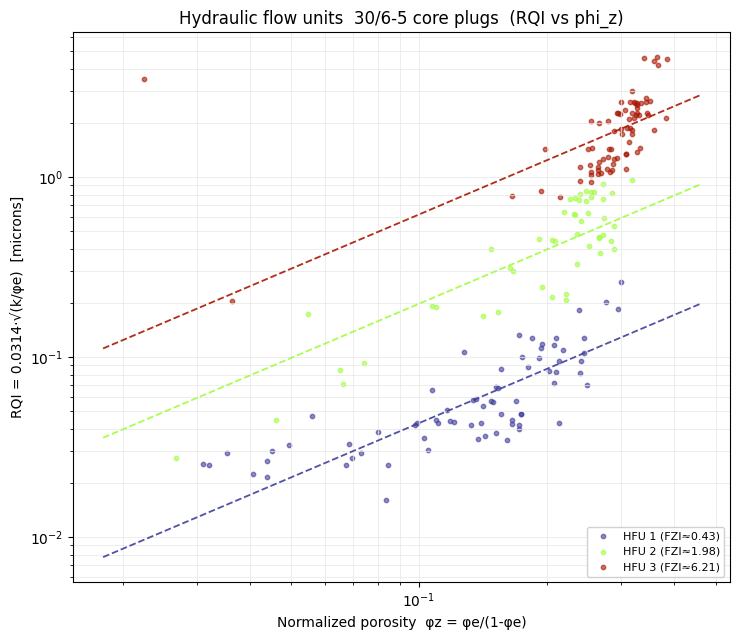

In [4]:
# Flow-unit (Amaefule) plot via the library plotter: RQI vs phi_z on log-log
# axes with a unit-slope FZI line per hydraulic flow unit. Clustered on the
# real core plugs, not the transform-derived log permeability.
from petrophys.evaluation import calculate_flow_units
from petrophys.visualization import create_flow_unit_plot

fu = calculate_flow_units(core_k, core_phi, n_units=3)

print('Number of flow units :', fu.n_units)
print('Samples per unit     :', list(fu.counts))
print('Mean FZI per unit    :', [round(float(x), 2) for x in fu.fzi_unit_mean])

fig = create_flow_unit_plot(result=fu, figsize=(7.5, 6.5),
                            title='Hydraulic flow units  30/6-5 core plugs  (RQI vs phi_z)')
plt.show()

## 3. Bulk-volume water (BVW) and moveable-hydrocarbon index (MHI)

- `calculate_bvw(phie, sw)` -> $BVW = \phi_e \times S_w$. A **constant** BVW with
  depth signals a rock at irreducible water (it will flow clean hydrocarbon);
  rising BVW signals a transition zone (it will make water).
- `calculate_mhi(sxo, sw)` -> $MHI = S_w / S_{xo}$. Rule of thumb: **MHI < 0.7**
  indicates moveable hydrocarbon (the filtrate flushed it away near the borehole);
  **MHI > 0.7** suggests little moveable hydrocarbon.

In [5]:
from petrophys.evaluation import calculate_bvw, calculate_mhi

bvw = calculate_bvw(phie, sw)
mhi = calculate_mhi(sxo, sw)

print('BVW  mean/std : %.4f / %.4f' % (np.nanmean(bvw), np.nanstd(bvw)))
above = depth < 2900.0
print('BVW  mean above / below 2900 m : %.3f / %.3f'
      % (np.nanmean(bvw[above]), np.nanmean(bvw[~above])))
print('MHI  mean     : %.3f' % np.nanmean(mhi))
frac_moveable = float(np.nanmean(mhi < 0.7))
print('Fraction of samples with MHI < 0.7 (moveable HC) : %.0f%%'
      % (100 * frac_moveable))
print()
print('Read: BVW is low and stable above ~2900 m (near irreducible) but rises')
print('below it - a transition zone. An MHI mean of %.2f, with only %.0f%% of'
      % (np.nanmean(mhi), 100 * frac_moveable))
print('samples under the 0.7 cutoff, says the hydrocarbon is only partly moveable.')

BVW  mean/std : 0.1157 / 0.0475
BVW  mean above / below 2900 m : 0.087 / 0.145
MHI  mean     : 0.946
Fraction of samples with MHI < 0.7 (moveable HC) : 29%

Read: BVW is low and stable above ~2900 m (near irreducible) but rises
below it - a transition zone. An MHI mean of 0.95, with only 29% of
samples under the 0.7 cutoff, says the hydrocarbon is only partly moveable.


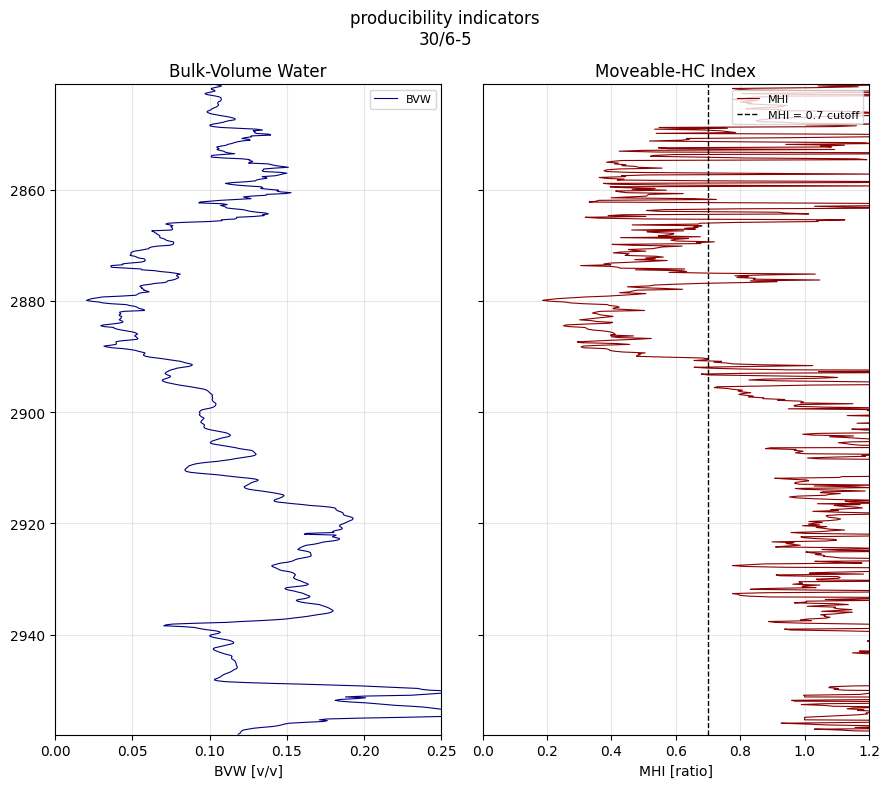

In [6]:
# Producibility indicators as a library LogPlot (2 tracks). Attach BVW and MHI
# to the sliced reservoir well; add the MHI cutoff on the returned axis.
from petrophys.visualization import LogPlot

res.add_curve('BVW', bvw, 'v/v', 'Bulk-volume water')
res.add_curve('MHI', mhi, 'ratio', 'Moveable-HC index Sw/Sxo')

lp = LogPlot(res, figsize=(9, 8))
lp.create_figure(n_tracks=2)

lp.add_curve(0, 'BVW', color='navy', linewidth=0.8, xlim=(0, 0.25))
lp.axes[0].set_title('Bulk-Volume Water')

lp.add_curve(1, 'MHI', color='darkred', linewidth=0.8, xlim=(0, 1.2))
lp.axes[1].axvline(0.7, color='k', ls='--', lw=1, label='MHI = 0.7 cutoff')
lp.axes[1].legend(fontsize=8, loc='upper right')
lp.axes[1].set_title('Moveable-HC Index')

lp.add_title('producibility indicators')
lp.set_depth_range(TOP, BASE)
lp.show()

## 4. Three-stage net pay

Net pay is built in three nested stages, each removing more rock:

1. **Net rock** - remove non-reservoir lithology (clay cutoff: $V_{cl} <$ cutoff).
2. **Net reservoir** - of the net rock, keep only what has enough storage
   (porosity cutoff: $\phi_e >$ cutoff).
3. **Net pay** - of the net reservoir, keep only what is hydrocarbon-bearing
   (saturation cutoff: $S_w <$ cutoff).

`NetPayModule` runs all three. Cutoffs left unset resolve to the
**curriculum standards** (`STANDARD_CUTOFFS`, one set per lithology family) -
the same numbers every notebook and workflow in this repo uses, so results are
comparable across chapters. `calculate_net_pay(well, ...)` is the convenience
wrapper that reads curves off the well; here we pass our computed arrays
explicitly to the module.

In [7]:
from petrophys.evaluation.net_pay import NetPayModule, STANDARD_CUTOFFS

# The library carries ONE set of standard cutoffs per lithology family - the
# same numbers every notebook and workflow in this curriculum uses:
print('Curriculum standard cutoffs:')
for fam, cuts in STANDARD_CUTOFFS.items():
    print('  %-9s : Vcl < %.2f, PHIE > %.2f, Sw < %.2f'
          % (fam, cuts['vcl_cutoff'], cuts['phie_cutoff'], cuts['sw_cutoff']))

# NetPayModule resolves unset cutoffs from its lithology automatically.
npm = NetPayModule(lithology='clastic')
print()
print('Module resolved (clastic)  : Vcl %.2f / PHIE %.2f / Sw %.2f'
      % (npm.vcl_cutoff, npm.phie_cutoff, npm.sw_cutoff))
result = npm.calculate(res, vcl=vcl, phie=phie, sw=sw)

print()
print('Gross thickness         : %6.1f m' % result.gross_thickness)
print('Net rock       thickness: %6.1f m' % result.net_rock_thickness)
print('Net reservoir  thickness: %6.1f m' % result.net_reservoir_thickness)
print('Net pay        thickness: %6.1f m' % result.net_pay_thickness)
print()
ntg = result.net_pay_thickness / result.gross_thickness
print('Net-to-gross (pay/gross): %.2f' % ntg)

Curriculum standard cutoffs:
  clastic   : Vcl < 0.40, PHIE > 0.08, Sw < 0.60
  carbonate : Vcl < 0.30, PHIE > 0.04, Sw < 0.70

Module resolved (clastic)  : Vcl 0.40 / PHIE 0.08 / Sw 0.60

Gross thickness         :  117.0 m
Net rock       thickness:   61.4 m
Net reservoir  thickness:   60.9 m
Net pay        thickness:   29.4 m

Net-to-gross (pay/gross): 0.25


### The net-pay flag track

The `NetPayResult` carries boolean masks (`net_rock`, `net_reservoir`, `net_pay`).
Plotting them as a stacked flag track next to the logs makes the three-stage
filtering visible: each stage is a subset of the one before it.

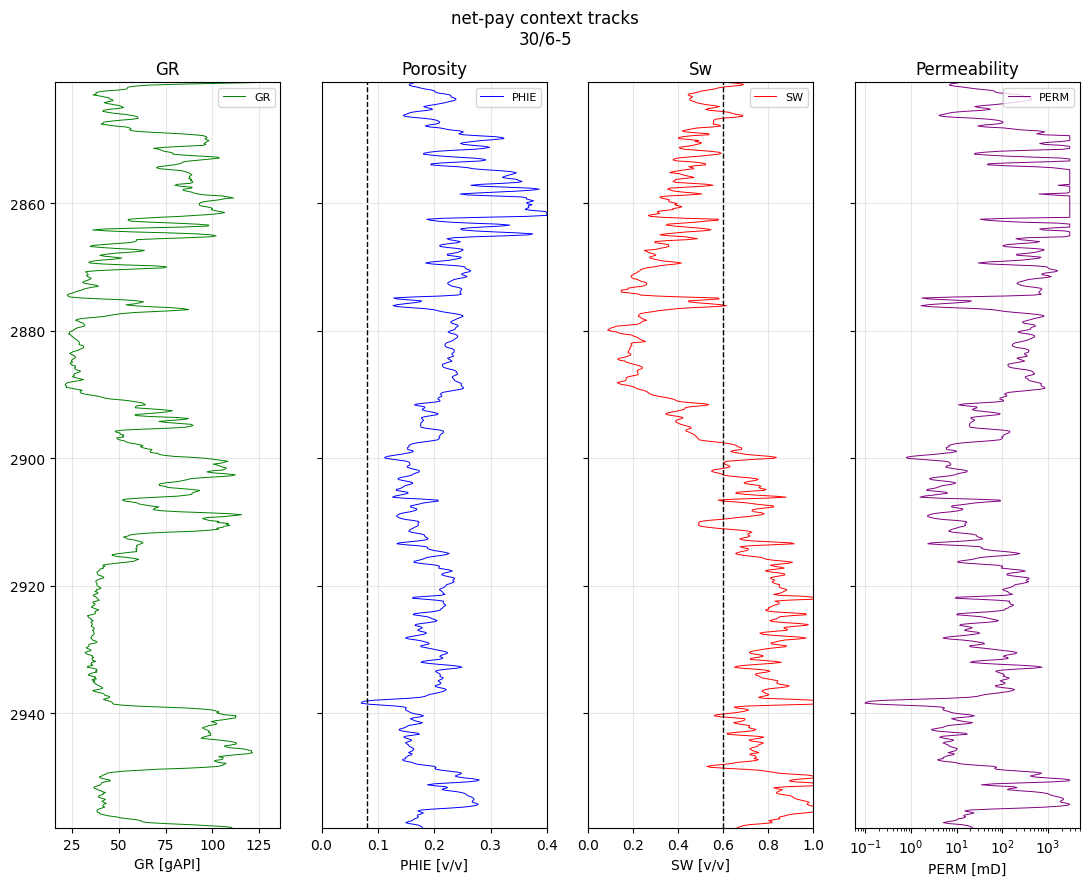

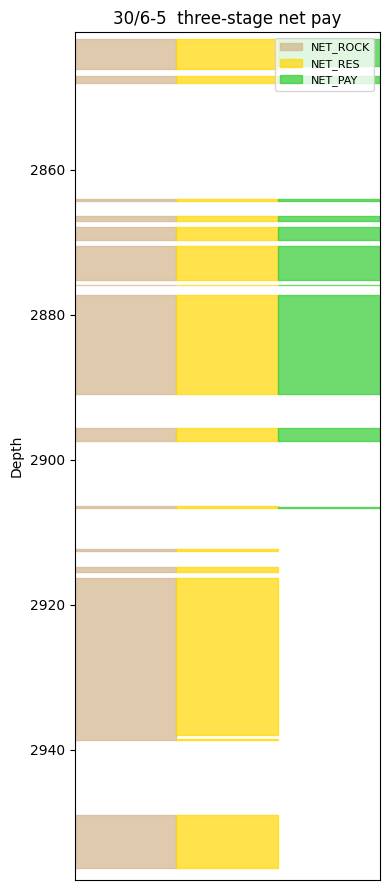

In [8]:
# Three-stage net pay. The flag track is drawn by the library plot_zone_flags
# helper (attach the net-rock/reservoir/pay masks as 0/1 flag curves), and the
# supporting GR/PHIE/Sw/permeability context is a library LogPlot.
from petrophys.visualization import LogPlot, plot_zone_flags

res.add_curve('PHIE', phie, 'v/v', 'Effective porosity')
res.add_curve('SW',   sw,   'v/v', 'Water saturation')
res.add_curve('PERM', perm, 'mD',  'Core-calibrated permeability')
res.add_curve('NET_ROCK', np.asarray(result.net_rock,      dtype=float), 'flag')
res.add_curve('NET_RES',  np.asarray(result.net_reservoir, dtype=float), 'flag')
res.add_curve('NET_PAY',  np.asarray(result.net_pay,       dtype=float), 'flag')

# Context tracks: GR, PHIE (with cutoff), Sw (with cutoff), permeability.
lp = LogPlot(res, figsize=(11, 9))
lp.create_figure(n_tracks=4)
lp.add_curve(0, 'GR',   color='green', linewidth=0.7)
lp.axes[0].set_title('GR')
lp.add_curve(1, 'PHIE', color='blue',  linewidth=0.7, xlim=(0, 0.4))
lp.axes[1].axvline(0.08, color='k', ls='--', lw=1); lp.axes[1].set_title('Porosity')
lp.add_curve(2, 'SW',   color='red',   linewidth=0.7, xlim=(0, 1))
lp.axes[2].axvline(0.60, color='k', ls='--', lw=1); lp.axes[2].set_title('Sw')
lp.add_curve(3, 'PERM', color='purple', linewidth=0.7, log_scale=True)
lp.axes[3].set_title('Permeability')
lp.add_title('net-pay context tracks')
lp.set_depth_range(TOP, BASE)
lp.show()

# Net-pay flag track via the library zone-flag plotter.
fig, ax = plot_zone_flags(
    res, flag_curves=['NET_ROCK', 'NET_RES', 'NET_PAY'],
    colors={'NET_ROCK': 'tan', 'NET_RES': 'gold', 'NET_PAY': 'limegreen'},
    depth_range=(TOP, BASE), figsize=(4, 9))
ax.set_title('30/6-5  three-stage net pay')
plt.show()

## 5. Volumetrics: HCPV, OOIP, OGIP

With net pay and pay-averaged porosity and $S_w$ in hand, we estimate hydrocarbon
in place. The summation functions use **field units** (acres, feet):

- `calculate_hcpv(area_acres, net_pay_ft, porosity, sw, bo, bg, ngi)` -> a rich
  `HCPVResult` (acre-ft, bbl, m3, OOIP, OGIP).
- `calculate_ooip(area_acres, net_pay_ft, porosity, sw, bo, recovery_factor)`
- `calculate_ogip(area_acres, net_pay_ft, porosity, sw, bg, recovery_factor)`

We average porosity and $S_w$ **over the net-pay samples only** (averaging over
non-pay would dilute the numbers), convert the net-pay thickness from metres to
feet, and assume a nominal drainage area.

In [9]:
from petrophys.evaluation.summaries import calculate_hcpv, calculate_ooip, calculate_ogip

pay = np.asarray(result.net_pay, dtype=bool)
phi_pay = float(np.nanmean(phie[pay]))
sw_pay  = float(np.nanmean(sw[pay]))
net_pay_ft = result.net_pay_thickness * 3.281   # metres -> feet
AREA_ACRES = 1000.0                              # nominal drainage area

print('Pay-averaged porosity : %.3f' % phi_pay)
print('Pay-averaged Sw       : %.3f' % sw_pay)
print('Net pay               : %.1f ft' % net_pay_ft)
print()

hcpv = calculate_hcpv(area_acres=AREA_ACRES, net_pay_ft=net_pay_ft,
                      porosity=phi_pay, sw=sw_pay)
print('HCPV : %.3e acre-ft | OOIP %.2f MMSTB | OGIP %.2f Bcf'
      % (hcpv.hcpv_acft, hcpv.ooip_stb / 1e6, hcpv.ogip_bcf))

ooip = calculate_ooip(AREA_ACRES, net_pay_ft, phi_pay, sw_pay, recovery_factor=0.30)
ogip = calculate_ogip(AREA_ACRES, net_pay_ft, phi_pay, sw_pay, recovery_factor=0.70)
print('OOIP recoverable @30%% RF : %.2f MMSTB' % (ooip['recoverable_stb'] / 1e6))
print('OGIP (gas case)          : keys ->', list(ogip.keys()))

Pay-averaged porosity : 0.224
Pay-averaged Sw       : 0.308
Net pay               : 96.5 ft

HCPV : 1.497e+04 acre-ft | OOIP 96.76 MMSTB | OGIP 130.38 Bcf
OOIP recoverable @30% RF : 29.03 MMSTB
OGIP (gas case)          : keys -> ['ogip_scf', 'ogip_mcf', 'ogip_mmcf', 'ogip_bcf', 'ogip_tcf', 'recoverable_scf', 'recoverable_bcf', 'recovery_factor']


## 6. Tie it together: the reservoir summary

Finally, collapse the whole evaluation into a one-line summary table - the kind of
row you would hand to a geologist or reservoir engineer.

In [10]:
summary = pd.DataFrame([{
    'Well'            : well.name,
    'Interval (m)'    : '%.0f-%.0f' % (TOP, BASE),
    'Gross (m)'       : round(result.gross_thickness, 1),
    'Net pay (m)'     : round(result.net_pay_thickness, 1),
    'N/G'             : round(result.net_pay_thickness / result.gross_thickness, 2),
    'PHIE_pay'        : round(phi_pay, 3),
    'Sw_pay'          : round(sw_pay, 3),
    'BVW_mean'        : round(float(np.nanmean(bvw)), 3),
    'k_pay_mean (mD)' : round(float(np.nanmean(perm[pay])), 0),
    'Flow units'      : int(fu.n_units),
    'OOIP (MMSTB)'    : round(hcpv.ooip_stb / 1e6, 1),
}])
print(summary.to_string(index=False))

  Well Interval (m)  Gross (m)  Net pay (m)  N/G  PHIE_pay  Sw_pay  BVW_mean  k_pay_mean (mD)  Flow units  OOIP (MMSTB)
30/6-5    2841-2958      117.0         29.4 0.25     0.224   0.308     0.116            342.0           3          96.8


### Reading the summary

This one row is the distilled output of the entire Part A pipeline: an interbedded
sand-shale package whose pay footage is clean sand, low pay-zone $S_w$ (so high
hydrocarbon saturation), a BVW that is near irreducible above ~2900 m but rises
through a transition zone below, an MHI of ~0.79 (only part of the hydrocarbon is
moveable), a healthy pay-zone permeability, and a handful of flow units. Every number traces back to a physical model you can
defend: $V_{cl}$ from GR, porosity from density-neutron, $S_w$ from Archie,
permeability from a **core-calibrated** transform, and volumetrics from
field-unit summation.

## 7. Validation against the operator's completion report

Net pay is cutoff arithmetic, so "is it right?" can only be answered against an
independent evaluation. For 30/6-5 one exists: Statoil's completion report
(petrophysical evaluation dated 13 Dec 1981, H.M. Strommevold) publishes a
zone-by-zone table for 2800-2980 m with its parameters stated: Archie with
$a=0.80$, $m=n=2$, $R_w=0.070$ ohm.m at 230 F, cutoffs $V_{sh}<0.40$,
$\phi>0.12$, and $S_w<0.65$ for pay. Their result: Ness 4.25 m pay, Etive
20.75 m, and the Drake sand essentially wet (net-sand $S_w=0.918$, 1.75 m pay).

Below we replicate their evaluation with the library, their parameters and
cutoffs verbatim. Two lessons come out of it. First, the main pay call is
confirmed: our Etive matches theirs to within ~1.3 m with pay porosity agreeing
to 0.002. Second, and more important: with an
under-estimated $R_w=0.03$ (a common textbook guess for North Sea sands), the
Drake sand (deep resistivity ~2 ohm.m at ~0.21 porosity, a classic wet
response) would book ~26 m of false pay. The operator's higher $R_w$ kills
it, and our own Pickett envelope from notebook 07 (0.047 ohm.m in the deeper,
hotter Statfjord) independently supports an $R_w$ in the 0.06-0.08 range at
Drake depth. $R_w$ is the single most consequential parameter in the chain.

In [11]:
# Replicate the operator's evaluation: their zones, cutoffs, and Archie
# parameters (a=0.80, m=n=2, Rw=0.070 ohm.m), our curves.
ev = well.depth_slice(2800.0, 2980.0)
d_ev    = ev.depth
gr_ev   = ev.get('GR').data
rhob_ev = ev.get('RHOB').data
nphi_ev = ev.get('NPHI').data
rt_ev   = ev.get('RDEP').data
step_ev = float(np.nanmedian(np.diff(d_ev)))

vcl_ev  = vcl_from_gr(gr_ev, np.nanpercentile(gr_ev, 5), np.nanpercentile(gr_ev, 95))
phie_ev = np.clip((density_porosity(rhob_ev) + neutron_porosity(nphi_ev)) / 2.0, 0.0, 0.40)
sw_ev   = archie(rt_ev, 0.070, phie_ev, a=0.80, m=2.0, n=2.0)

# Operator's table: zone -> (top, base, net sand m, net pay m, pay phi, pay Sw)
statoil = {
    'Ness'  : (2841.0, 2865.0,  5.50,  4.25, 0.177, 0.535),
    'Etive' : (2865.0, 2895.0, 25.75, 20.75, 0.228, 0.198),
    'Drake' : (2895.0, 2939.0, 22.75,  1.75, 0.200, 0.551),
}
print('zone     ours: net    pay  payPHI  paySW   | Statoil: net    pay  payPHI  paySW')
tot_ours = tot_stat = 0.0
for name, (z0, z1, ns, np_, pp, ps) in statoil.items():
    m   = (d_ev >= z0) & (d_ev < z1)
    ok  = m & np.isfinite(vcl_ev) & np.isfinite(phie_ev) & np.isfinite(sw_ev)
    net = ok & (vcl_ev < 0.40) & (phie_ev > 0.12)
    pay = net & (sw_ev < 0.65)
    n_m, p_m = net.sum() * step_ev, pay.sum() * step_ev
    tot_ours += p_m; tot_stat += np_
    print('%-8s %10.2f %6.2f %7.3f %6.3f   |        %6.2f %6.2f %7.3f %6.3f'
          % (name, n_m, p_m, np.nanmean(phie_ev[pay]), np.nanmean(sw_ev[pay]),
             ns, np_, pp, ps))
print('TOTAL pay: ours %.1f m vs operator 26.75 m' % tot_ours)
print()
print('Counterfactual, same zones with an under-estimated Rw=0.03: the wet Drake books as pay.')
sw_low = archie(rt_ev, 0.03, phie_ev, a=0.80, m=2.0, n=2.0)
for name, (z0, z1, *_ ) in statoil.items():
    m   = (d_ev >= z0) & (d_ev < z1)
    ok  = m & np.isfinite(vcl_ev) & np.isfinite(phie_ev) & np.isfinite(sw_low)
    pay = ok & (vcl_ev < 0.40) & (phie_ev > 0.12) & (sw_low < 0.65)
    print('  %-6s pay with Rw=0.03 : %6.2f m' % (name, pay.sum() * step_ev))

zone     ours: net    pay  payPHI  paySW   | Statoil: net    pay  payPHI  paySW
Ness           7.31   7.01   0.208  0.523   |          5.50   4.25   0.177  0.535
Etive         22.09  22.09   0.230  0.236   |         25.75  20.75   0.228  0.198
Drake         26.05   2.59   0.208  0.508   |         22.75   1.75   0.200  0.551
TOTAL pay: ours 31.7 m vs operator 26.75 m

Counterfactual, same zones with an under-estimated Rw=0.03: the wet Drake books as pay.
  Ness   pay with Rw=0.03 :   7.31 m
  Etive  pay with Rw=0.03 :  22.09 m
  Drake  pay with Rw=0.03 :  25.59 m


## Pitfalls & parameter choices

- **Average over pay, not over gross.** Diluting porosity/$S_w$ with non-pay
  samples silently deflates OOIP.
- **Cutoffs are decisions, not constants.** The `Cutoffs` defaults are a starting
  point; net pay is sensitive to them, so document and justify the values you use.
- **RQI/FZI inherit permeability uncertainty.** Because $RQI \propto \sqrt{k}$, a
  factor-of-2 error in $k$ is only a 40% error in RQI - FZI is more robust than raw
  $k$, which is why flow units are a stable way to zone a reservoir.
- **BVW constancy is diagnostic, not guaranteed.** Rising BVW down-section is a real
  transition zone; don't force a single water contact through it.
- **Field units in volumetrics.** `calculate_hcpv` and friends expect acres and
  feet - convert metric thicknesses first (x3.281).

## Recap

- **RQI / $\phi_z$ / FZI** turn porosity and permeability into a hydraulic quality
  metric; clustering FZI gives **flow units** that zone the reservoir.
- **BVW** ($\phi_e S_w$) near-constant = rock at irreducible water; **MHI**
  ($S_w/S_{xo}$) $< 0.7$ = moveable hydrocarbon.
- **Net pay** is a three-stage filter: net rock (clay) -> net reservoir (porosity)
  -> net pay (saturation), via `NetPayModule` with `Cutoffs`.
- **Volumetrics** (`calculate_hcpv/ooip/ogip`) convert pay thickness, porosity and
  $S_w$ into hydrocarbon in place - in field units.
- The final summary row is the whole Part A pipeline distilled to defensible
  numbers.

## Try it yourself

> **Exercise 1.** Tighten the porosity cutoff from the standard 0.08 to the
> operator's 0.12, and $S_w$ from 0.60 to 0.50. How do net-pay thickness and OOIP
> respond? Which cutoff is the net pay more sensitive to here?
>
> **Exercise 2.** Re-run `calculate_flow_units` with `n_units=4`. Do the extra
> units carve out genuinely different rock (look at the FZI plot), or just split an
> existing cluster?
>
> **Exercise 3.** Sweep the drainage area from 500 to 2000 acres and plot OOIP vs
> area. Since OOIP is linear in area, what does that tell you about which input
> dominates a volumetric estimate's uncertainty?

## What's next

This closes Part A - Foundations. You now have an end-to-end deterministic
petrophysical workflow: from raw logs to clay volume, porosity, saturation,
permeability, and finally reservoir quality, net pay and volumetrics. Part B builds
on this with saturation-height modelling and integration with core and NMR.